# Comparación de modelos sobre `test.jsonl`

In [ ]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "evaluation").exists() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from evaluation.run_baseline import (
    aggregate_by,
    calibration,
    k_values_for,
    load_tasks,
    load_traces,
    summarize_model,
)

LEVELS = ["easy", "medium", "hard", "expert"]
K = 8

# Acepta tanto reportes .json (run_baseline / run_hf) como trazas .jsonl (completas o parciales).
MODELS = {
    "Base (Ollama q4)": "outputs/baseline_test/baseline.json",
    "SFT (LoRA)":       "outputs/sft_lora_test/traces_sft_lora_test.jsonl",
    # "SFT (LoRA)":       "outputs/sft_lora_test/sft_lora.json",
    # "DPO (LoRA)":       "outputs/dpo_lora_test/dpo_lora.json",
    # "GRPO binaria":     "outputs/grpo_binaria_test/grpo_binaria.json",
    # "GRPO relajada":    "outputs/grpo_relajada_test/grpo_relajada.json",
    # "GRPO estricta":    "outputs/grpo_estricta_test/grpo_estricta.json",
}

In [3]:
tasks = load_tasks("test")

def load_summary(path_str):
    p = Path(path_str)
    if not p.exists():
        print(f"[omitido] No existe: {p}")
        return None
    if p.suffix == ".json":
        data = json.loads(p.read_text(encoding="utf-8"))
        return next(iter(data["models"].values()))
    done = load_traces(p)
    complete = [t for t in tasks if all((t.id, s) in done for s in range(K))]
    episodes = [[done[(t.id, s)] for s in range(K)] for t in complete]
    return summarize_model(complete, episodes, K)

summaries = {}
for name, path in MODELS.items():
    s = load_summary(path)
    if s and s.get("n_tasks", 0) > 0:
        summaries[name] = s
        tag = "completo" if s["n_tasks"] == len(tasks) else f"parcial {s['n_tasks']}/{len(tasks)}"
        print(f"{name:<20} -> {s['n_tasks']} tareas x k={s['samples_per_task']} ({tag})")

Base (Ollama q4)     -> 602 tareas x k=8 (completo)
SFT (LoRA)           -> 97 tareas x k=8 (parcial 97/602)


## 1. Tabla resumen global

In [4]:
rows = []
for name, s in summaries.items():
    ov = s["overall"]
    bl = s["by_block"]
    cal = s["calibration"]["all"]
    tu = s["tool_usage"]
    rows.append({
        "Modelo": name,
        "Tareas": s["n_tasks"],
        "pass@1": ov.get("pass@1"),
        "pass@2": ov.get("pass@2"),
        "pass@4": ov.get("pass@4"),
        "pass@8": ov.get("pass@8"),
        "seen@1": bl.get("seen", {}).get("pass@1"),
        "heldout@1": bl.get("heldout", {}).get("pass@1"),
        "Nunca": cal["never_solved"],
        "Zona": cal["learnable"],
        "Siempre": cal["always_solved"],
        "Fmt OK": tu["valid_format_rate"],
        "SQL Ejec": tu["executable_sql_rate"],
        "Turnos": tu["avg_turns"],
    })

df_global = pd.DataFrame(rows)
df_global

,Modelo,Tareas,pass@1,pass@2,pass@4,pass@8,seen@1,heldout@1,Nunca,Zona,Siempre,Fmt OK,SQL Ejec,Turnos
0,Base (Ollama q4),602,0.4817,0.6004,0.6874,0.7475,0.4471,0.5246,0.2525,0.5681,0.1794,0.8368,0.3905,2.9321
1,SFT (LoRA),97,0.6753,0.7467,0.7937,0.8247,0.7372,0.6120,0.1753,0.3402,0.4845,0.9510,0.6679,2.4162


## 2. Comparación justa sobre tareas en común

Se calcula esta tabla, que evalúa todos los modelos sobre exactamente el mismo subconjunto de `task_id` (Si hay trazas parciales, la |tasks| calculadas < 602 tareas).

In [5]:
common_ids = set.intersection(*(
    {r["task_id"] for r in s["per_task"]} for s in summaries.values()
))
print(f"Tareas en común: {len(common_ids)} / {len(tasks)}")

common_rows = []
common_by_diff = {}
common_by_block = {}

for name, s in summaries.items():
    sub = [r for r in s["per_task"] if r["task_id"] in common_ids]
    ks = k_values_for(min(r["n"] for r in sub), K)
    by_d = aggregate_by(sub, "difficulty", ks)
    by_b = aggregate_by(sub, "block", ks)
    cal = calibration(sub)["all"]
    common_by_diff[name] = by_d
    common_by_block[name] = by_b
    common_rows.append({
        "Modelo": name,
        "Tareas": len(sub),
        "pass@1": by_d["all"].get("pass@1"),
        "pass@2": by_d["all"].get("pass@2"),
        "pass@4": by_d["all"].get("pass@4"),
        "pass@8": by_d["all"].get("pass@8"),
        "seen@1": by_b.get("seen", {}).get("pass@1"),
        "heldout@1": by_b.get("heldout", {}).get("pass@1"),
        "Nunca": cal["never_solved"],
        "Zona": cal["learnable"],
        "Siempre": cal["always_solved"],
    })

df_common = pd.DataFrame(common_rows)
df_common

Tareas en común: 97 / 602


,Modelo,Tareas,pass@1,pass@2,pass@4,pass@8,seen@1,heldout@1,Nunca,Zona,Siempre
0,Base (Ollama q4),97,0.5180,0.6289,0.7212,0.8041,0.4872,0.5495,0.1959,0.5670,0.2371
1,SFT (LoRA),97,0.6753,0.7467,0.7937,0.8247,0.7372,0.6120,0.1753,0.3402,0.4845


## 3. Desglose por dificultad y generalización (`seen` vs `heldout`)

,easy,medium,hard,expert,all
Base (Ollama q4),0.8674,0.5202,0.2024,0.1042,0.5180
SFT (LoRA),0.9167,0.7379,0.4167,0.3021,0.6753


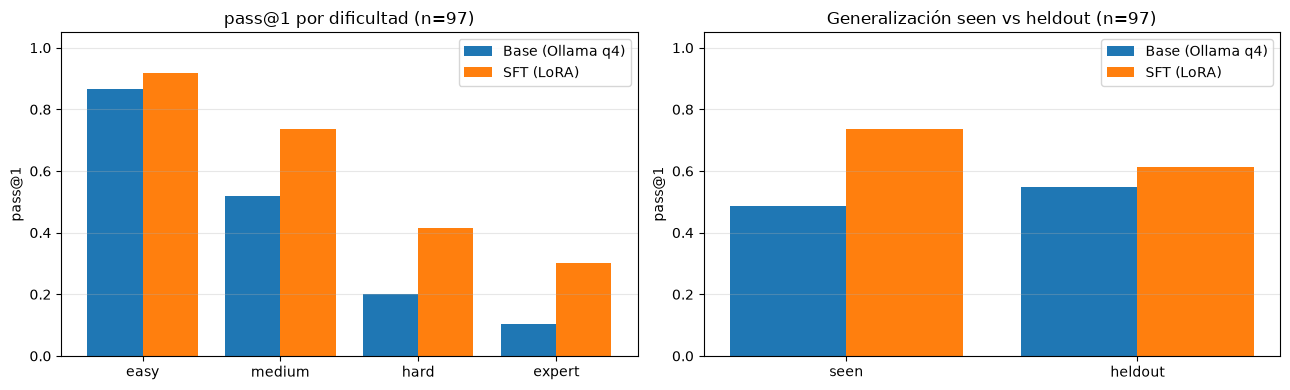

In [6]:
diff_table = pd.DataFrame({
    name: {lvl: by_d.get(lvl, {}).get("pass@1") for lvl in LEVELS + ["all"]}
    for name, by_d in common_by_diff.items()
}).T
display(diff_table)

names = list(summaries.keys())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

x = np.arange(len(LEVELS))
w = 0.8 / max(1, len(names))
for i, name in enumerate(names):
    vals = [common_by_diff[name].get(lvl, {}).get("pass@1", 0) for lvl in LEVELS]
    axes[0].bar(x + (i - (len(names) - 1) / 2) * w, vals, width=w, label=name)
axes[0].set_xticks(x)
axes[0].set_xticklabels(LEVELS)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("pass@1")
axes[0].set_title(f"pass@1 por dificultad (n={len(common_ids)})")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

blocks = ["seen", "heldout"]
xb = np.arange(len(blocks))
for i, name in enumerate(names):
    vals = [common_by_block[name].get(b, {}).get("pass@1", 0) for b in blocks]
    axes[1].bar(xb + (i - (len(names) - 1) / 2) * w, vals, width=w, label=name)
axes[1].set_xticks(xb)
axes[1].set_xticklabels(blocks)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("pass@1")
axes[1].set_title(f"Generalización seen vs heldout (n={len(common_ids)})")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Etapas intermedias (SQL ejecutable → resultado = GT → respuesta correcta)

In [ ]:
stage_rows = []
for name, s in summaries.items():
    sr = s.get("stage_rates", {}).get("all")
    if sr:
        stage_rows.append({
            "Modelo": name,
            "Episodios": sr["n_episodes"],
            "SQL ejecutable": sr["sql_executable"],
            "Resultado = GT": sr["result_correct"],
            "Respuesta correcta": sr["answer_correct"],
            "Brecha SQL->GT": round(sr["sql_executable"] - sr["result_correct"], 4),
            "Brecha GT->Ans": round(sr["result_correct"] - sr["answer_correct"], 4),
        })

df_stages = pd.DataFrame(stage_rows)
display(df_stages) if not df_stages.empty else print("Ningún modelo tiene stage_rates aún.")

,Modelo,Episodios,SQL ejecutable,Resultado = GT,Respuesta correcta,Brecha SQL->GT,Brecha GT->Ans
0,SFT (LoRA),776,0.8995,0.6765,0.6753,0.223,0.0012


## 5. Exportar tabla para el informe

In [ ]:
out_csv = Path("outputs/comparacion_modelos.csv")
df_common.to_csv(out_csv, index=False)
print(f"Guardado en {out_csv}")
print(df_common.to_string(index=False))